# v6 hull — CFD ramp to 20 mph: live viewer

Reads the OpenFOAM 14 run on the server (`hav-v6-ramp20`): towed v6 hull, accelerating frame,
0 → 20 mph between 1 s and 11 s, held to 16 s. Half model; forces here are doubled to the whole boat.

**Use:** pick the **Python 3.13** kernel (needs `pyvista[jupyter]`, `imageio-ffmpeg`; see `requirements-viz.txt`), then *Run All*.
Each run pulls the newest data from the server (`SYNC = True`) — run it again any time while the simulation is going.

Caveats: no propeller thrust; only the filled rows of the v6 loading sheet (153.595 lb); calm water;
~8 mm mesh. While the speed is still changing, the drag includes a small force from accelerating the
water around the hull — the steady 20 mph hold (11–16 s) gives the clean resistance.

In [74]:
%matplotlib inline
import csv, os, pathlib, subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv
from IPython.display import display

HERE = pathlib.Path.cwd()                      # this notebook's folder
CASE = HERE / 'results-ramp20'                 # local copy made by sync_results.sh
SAVITSKY = (HERE.parents[1] / 'hydrodynamics-savitsky' / 'v6-2026-11-11' / 'results' / 'sensitivity'
            / 'study-20261112T010624310036Z' / 'curves.csv')
SYNC = True             # pull the newest data from the server first (~3.5 MB per new animation frame)
WATERLINE = 0.1608      # m, undisturbed free surface
RHO_WATER, RHO_AIR, G = 998.2, 1.196, 9.81

sys.path.insert(0, str(HERE))
import postprocess

# 3D views show as plain images in the notebook (fast, never hangs in VS Code).
# For a rotatable view, set OPEN_IN_BROWSER = True in the 3D cell: it opens a standalone page in your browser.
pv.set_jupyter_backend('static')

## 1 · Pull the latest data and summarise

In [75]:
if SYNC:
    r = subprocess.run(['sh', 'sync_results.sh'], cwd=HERE, capture_output=True, text=True)
    print((r.stdout + r.stderr).strip()[-800:])

postprocess.summary(CASE)
rows = list(csv.DictReader(open(CASE / 'results.csv')))
res = {k: np.array([float(r[k]) for r in rows]) for k in rows[0]}
log = (CASE / 'log.foamRun').read_text(errors='replace') if (CASE / 'log.foamRun').exists() else ''
finished = log.rstrip().endswith('End')
print(f"simulated {res['time_s'][-1]:.3f} s of 16 s  |  speed {res['speed_mph'][-1]:.2f} mph  |  "
      f"trim {res['trim_deg'][-1]:.2f}°  |  rise {res['rise_mm'][-1]:+.1f} mm  |  drag {res['drag_N'][-1]:.1f} N"
      + ('  |  FINISHED' if finished else '  |  still running'))

freeSurface: 221 frames, t = 0.0..11.0 s
hull: 221 frames, t = 0.0..11.0 s
wrote /Users/patri/Programming/boat/hav/hull/hydrodynamics-cfd/v6-2026-11-11/results-ramp20/results.csv (9240 rows)
simulated 11.046 s of 16 s  |  speed 20.00 mph  |  trim 4.87°  |  rise +107.4 mm  |  drag 105.7 N  |  still running


## 2 · Time histories

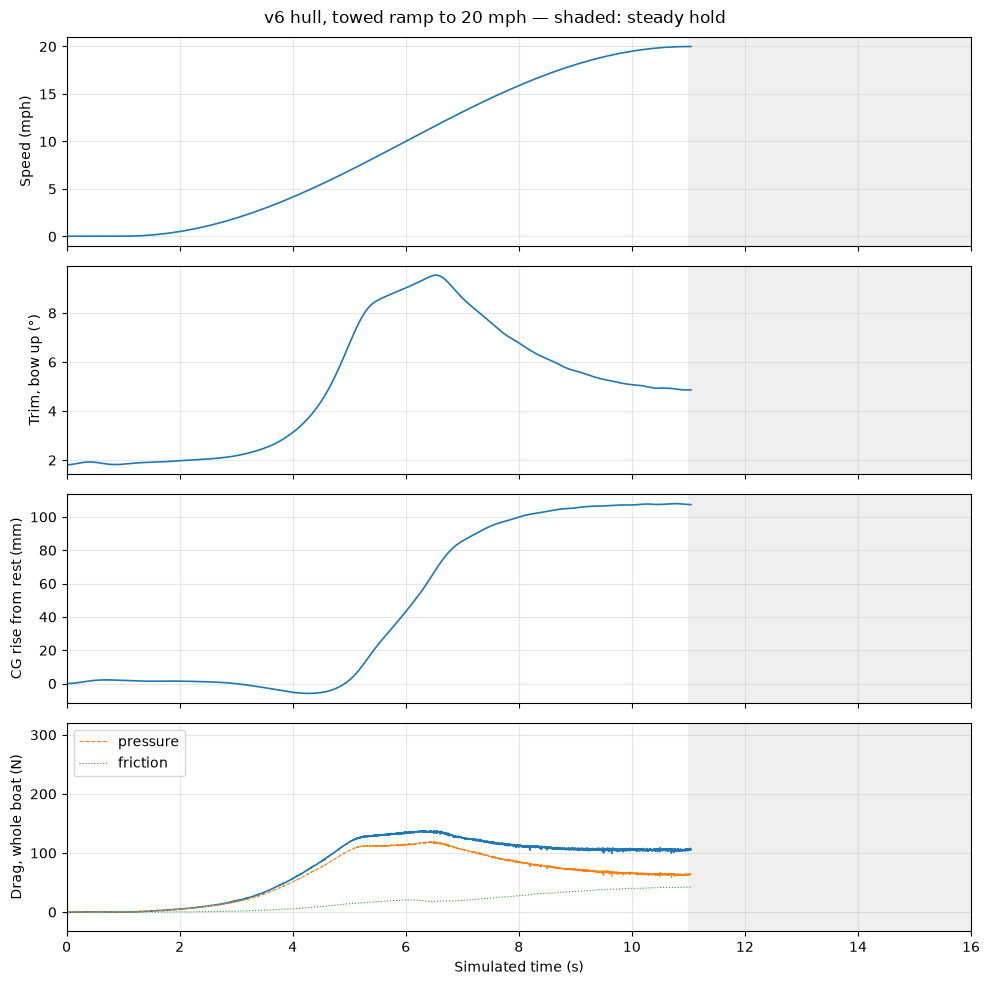

In [76]:
fig, axs = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
for ax, key, label in zip(axs, ['speed_mph', 'trim_deg', 'rise_mm', 'drag_N'],
                          ['Speed (mph)', 'Trim, bow up (°)', 'CG rise from rest (mm)', 'Drag, whole boat (N)']):
    ax.plot(res['time_s'], res[key], lw=1.2)
    ax.set_ylabel(label); ax.grid(alpha=.3)
axs[3].plot(res['time_s'], res['pressure_drag_N'], lw=.8, ls='--', label='pressure')
axs[3].plot(res['time_s'], res['friction_drag_N'], lw=.8, ls=':', label='friction')
axs[3].legend(loc='upper left')
for ax in axs:
    ax.axvspan(11, 16, color='0.85', alpha=.4, lw=0)   # steady 20 mph hold
axs[0].set_xlim(0, 16); axs[-1].set_xlabel('Simulated time (s)')
fig.suptitle('v6 hull, towed ramp to 20 mph — shaded: steady hold'); fig.tight_layout()
display(fig); plt.close(fig)

## 3 · Against the Savitsky baseline

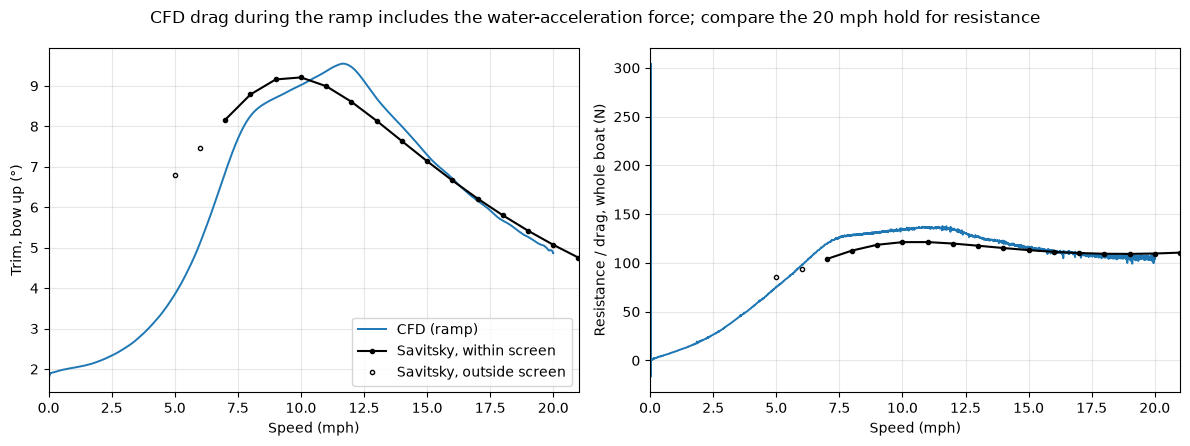

In [77]:
sav = [r for r in csv.DictReader(open(SAVITSKY)) if r['scenario'] == 'Baseline' and r['trim_deg']]
sv = np.array([float(r['speed_mph']) for r in sav]); st = np.array([float(r['trim_deg']) for r in sav])
sr = np.array([float(r['resistance_n']) for r in sav]); ok = np.array([r['status'] == 'within_screen' for r in sav])

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, cfd, s, label in [(axs[0], res['trim_deg'], st, 'Trim, bow up (°)'),
                          (axs[1], res['drag_N'], sr, 'Resistance / drag, whole boat (N)')]:
    ax.plot(res['speed_mph'], cfd, lw=1.4, label='CFD (ramp)')
    ax.plot(sv[ok], s[ok], 'o-', ms=3, color='k', label='Savitsky, within screen')
    ax.plot(sv[~ok], s[~ok], 'o', ms=3, mfc='none', color='k', label='Savitsky, outside screen')
    ax.set_xlabel('Speed (mph)'); ax.set_ylabel(label); ax.grid(alpha=.3); ax.set_xlim(0, 21)
axs[0].legend()
fig.suptitle('CFD drag during the ramp includes the water-acceleration force; compare the 20 mph hold for resistance')
fig.tight_layout()
display(fig); plt.close(fig)

## 4 · 3D view

In [78]:
ANIM = CASE / 'postProcessing' / 'animation'
FRAMES = sorted((d for d in ANIM.iterdir() if d.is_dir()), key=lambda d: float(d.name))
if not finished:
    FRAMES = FRAMES[:-1]     # newest frame may still be being written on the server
body = postprocess.rows(next((CASE / 'postProcessing').glob('rigidBodyState/*/hull.dat')))
body_t = np.array([r[0] for r in body]); body_trim = np.array([r[5] for r in body])

def read_vtk(path):
    """Read OpenFOAM's legacy ASCII VTK surfaces. (VTK's own reader drops the data arrays when a
    value is below the float32 range, e.g. 1.4e-45, which OpenFOAM writes for near-zero numbers.)"""
    tok = path.read_text().split()
    i = tok.index('POINTS'); n = int(tok[i + 1])
    pts = np.array(tok[i + 3:i + 3 + 3 * n], float).reshape(n, 3)
    j = tok.index('POLYGONS'); size = int(tok[j + 2])
    mesh = pv.PolyData(pts, np.array(tok[j + 3:j + 3 + size], int))
    k = tok.index('FIELD'); k += 3
    for _ in range(int(tok[k - 1])):
        name, ncomp, ntup = tok[k], int(tok[k + 1]), int(tok[k + 2])
        vals = np.array(tok[k + 4:k + 4 + ncomp * ntup], float)
        mesh[name] = vals.reshape(ntup, ncomp) if ncomp > 1 else vals
        k += 4 + ncomp * ntup
    return mesh

def label(d):
    t = float(d.name)
    trim = body_trim[np.argmin(abs(body_t - t))]
    return f't = {t:5.2f} s   {postprocess.speed_at(CASE, t):5.2f} mph   trim {trim:4.1f}°'

def load_frame(d, window=(-4, 4, -2.5, 0.01)):
    # Whole boat (half model mirrored about the centreline); hull coloured by gauge pressure,
    # water surface by elevation above the starting waterline
    hull = read_vtk(d / 'hull.vtk')
    rho = hull['alpha.water'] * RHO_WATER + (1 - hull['alpha.water']) * RHO_AIR
    hull['pressure_kPa'] = (hull['p_rgh'] - rho * G * hull.points[:, 2]) / 1000
    hull = hull.merge(hull.reflect((0, 1, 0), point=(0, 0, 0)))
    fs = read_vtk(d / 'freeSurface.vtk').clip_box([*window, -1, 1], invert=False)
    fs['elevation_mm'] = (fs.points[:, 2] - WATERLINE) * 1000
    fs = fs.merge(fs.reflect((0, 1, 0), point=(0, 0, 0)))
    return hull, fs

def add_scene(p, hull, fs, text, p_max=6.0):
    p.add_mesh(fs, scalars='elevation_mm', cmap='RdBu_r', clim=(-60, 60), opacity=0.85,
               scalar_bar_args=dict(title='water surface (mm)', position_x=0.05, width=0.35))
    p.add_mesh(hull, scalars='pressure_kPa', cmap='viridis', clim=(0, p_max),
               scalar_bar_args=dict(title='hull pressure (kPa)', position_x=0.55, width=0.35))
    p.add_text(text, font_size=11)

SIDE_VIEW = [(-2.2, -3.6, 1.4), (0.9, 0, 0.1), (0, 0, 1)]
print(f'{len(FRAMES)} frames, t = {FRAMES[0].name} … {FRAMES[-1].name} s')

def wetted_p_max(hull):
    # colour-scale top for one frame: 99th percentile of pressure on the wetted hull
    wet = hull['alpha.water'] > 0.5
    return max(1.0, float(np.percentile(hull['pressure_kPa'][wet], 99))) if wet.any() else 1.0

220 frames, t = 0 … 10.95 s


Pick a time (`None` = newest). Set `OPEN_IN_BROWSER = True` for a view you can rotate and zoom (opens in your browser).

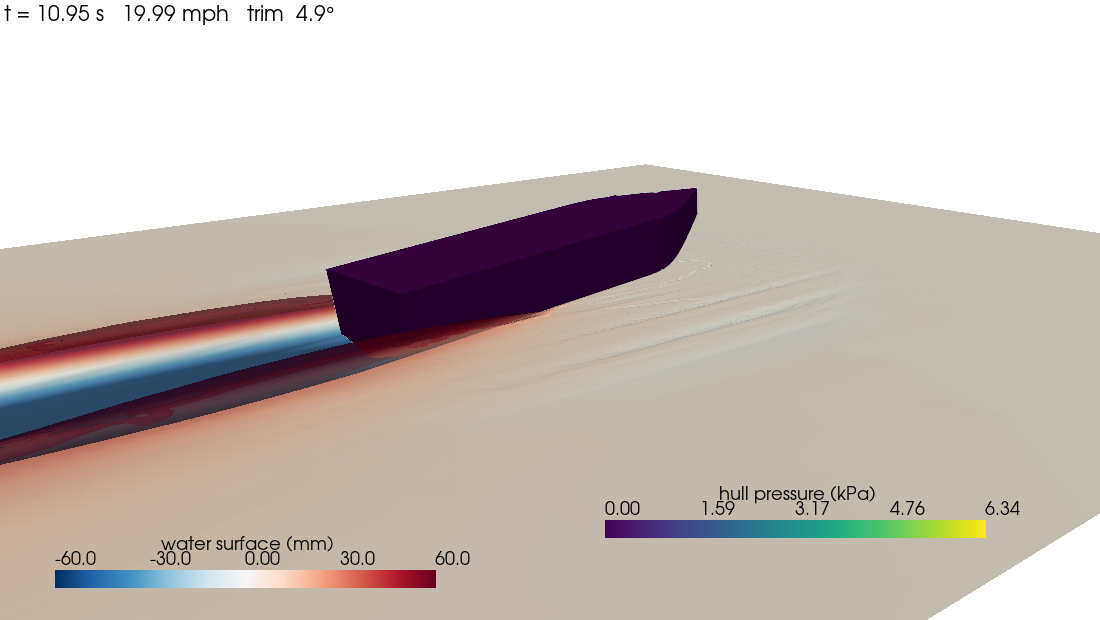

In [79]:
FRAME_TIME = None        # e.g. 6.0; None = newest
OPEN_IN_BROWSER = False  # True: also open a rotatable 3D view in your web browser

d = FRAMES[-1] if FRAME_TIME is None else min(FRAMES, key=lambda d: abs(float(d.name) - FRAME_TIME))
hull, fs = load_frame(d)
p = pv.Plotter(window_size=(1100, 620))
add_scene(p, hull, fs, label(d), p_max=wetted_p_max(hull))
p.camera_position = SIDE_VIEW
if OPEN_IN_BROWSER:
    import webbrowser
    page = CASE / f'view-{d.name}s.html'
    p.export_html(str(page))
    webbrowser.open(page.as_uri())
    print('opened', page)
p.show()

Bottom pressure — where the lift comes from (looking up at the hull, bow to the right).

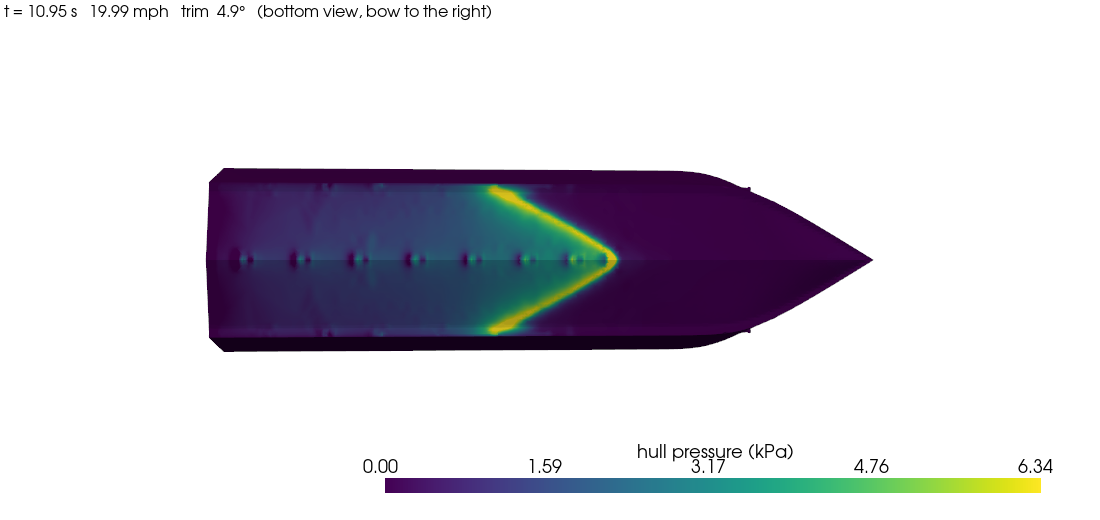

In [80]:
p = pv.Plotter(window_size=(1100, 520))
p.add_mesh(hull, scalars='pressure_kPa', cmap='viridis', clim=(0, wetted_p_max(hull)),
           scalar_bar_args=dict(title='hull pressure (kPa)'))
p.add_text(label(d) + '   (bottom view, bow to the right)', font_size=11)
p.view_vector((0, 0, -1), viewup=(0, -1, 0))
p.reset_camera(); p.camera.zoom(1.4)
p.show()

## 5 · Animation (MP4)
Renders every `STRIDE`-th frame (frames are 0.05 s apart). Takes a minute or two for the full run.

In [81]:
STRIDE = 4               # 4 -> one frame per 0.2 s of simulated time
FPS = 10
P_MAX_ANIM = 6.0      # kPa, fixed colour scale so frames are comparable
out = CASE / 'ramp.mp4'
p = pv.Plotter(off_screen=True, window_size=(1280, 720))
p.open_movie(str(out), framerate=FPS)
for d in FRAMES[::STRIDE]:
    p.clear()
    add_scene(p, *load_frame(d), label(d), p_max=P_MAX_ANIM)
    p.camera_position = SIDE_VIEW
    p.write_frame()
p.close()
from IPython.display import Video
print(out)
Video(str(out), embed=True, width=900)

/Users/patri/Programming/boat/hav/hull/hydrodynamics-cfd/v6-2026-11-11/results-ramp20/ramp.mp4
